In [1]:
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageFile
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import resnet18
from torchvision.transforms import InterpolationMode

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Paths
CSV_PATH = Path("../raw/airbus-ship-detection/train_ship_segmentations_v2.csv")
DATA_DIR = Path("../raw/airbus-ship-detection/train_v2")

SPLIT_DIR = Path("../splits")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_SPLIT_PATH = SPLIT_DIR / "train.csv"
VAL_SPLIT_PATH = SPLIT_DIR / "validation.csv"
TEST_SPLIT_PATH = SPLIT_DIR / "test.csv"

In [3]:
if all(
    path.exists()
    for path in [
        TRAIN_SPLIT_PATH,
        VAL_SPLIT_PATH,
        TEST_SPLIT_PATH,
    ]
):
    train_df = pd.read_csv(TRAIN_SPLIT_PATH)
    val_df = pd.read_csv(VAL_SPLIT_PATH)
    test_df = pd.read_csv(TEST_SPLIT_PATH)

    print("Loaded existing dataset splits.")

else:
    annotations = pd.read_csv(CSV_PATH)

    labels_df = (
        annotations.groupby("ImageId")["EncodedPixels"]
        .apply(lambda x: int(x.notna().any()))
        .reset_index(name="has_ship")
    )

    image_ids = {p.name for p in DATA_DIR.glob("*.jpg")}
    annotation_ids = set(labels_df["ImageId"])

    assert image_ids == annotation_ids, "Image/annotation mismatch"

    # 70% training, 30% temporary
    train_df, temp_df = train_test_split(
        labels_df,
        test_size=0.30,
        random_state=42,
        stratify=labels_df["has_ship"],
    )

    # Split remaining 30% equally
    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        random_state=42,
        stratify=temp_df["has_ship"],
    )

    train_df.to_csv(TRAIN_SPLIT_PATH, index=False)
    val_df.to_csv(VAL_SPLIT_PATH, index=False)
    test_df.to_csv(TEST_SPLIT_PATH, index=False)

In [4]:
# Verify no overlap
train_ids = set(train_df["ImageId"])
val_ids = set(val_df["ImageId"])
test_ids = set(test_df["ImageId"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

In [5]:
# Verify complete dataset coverage
all_split_ids = train_ids | val_ids | test_ids
actual_image_ids = {p.name for p in DATA_DIR.glob("*.jpg")}

assert all_split_ids == actual_image_ids
assert len(all_split_ids) == len(actual_image_ids)

In [6]:
# Verify expected 70/15/15 split proportions
total = len(all_split_ids)

assert abs(len(train_df) / total - 0.70) < 0.01
assert abs(len(val_df) / total - 0.15) < 0.01
assert abs(len(test_df) / total - 0.15) < 0.01

In [7]:
# Display split sizes
print("\nDataset split sizes:")
print(
    f"Training:   {len(train_df):,}"
    + f" ({len(train_df) / len(all_split_ids) * 100:.2f}%)"
)
print(
    f"Validation: {len(val_df):,}"
    + f" ({len(val_df) / len(all_split_ids) * 100:.2f}%)"
)
print(
    f"Testing:    {len(test_df):,}"
    + f" ({len(test_df) / len(all_split_ids) * 100:.2f}%)"
)


Dataset split sizes:
Training:   134,789 (70.00%)
Validation: 28,883 (15.00%)
Testing:    28,884 (15.00%)


In [8]:
# Display class distributions
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df),
]:
    print(f"\n{name} class distribution:")
    print(df["has_ship"].value_counts().rename({0: "No Ship", 1: "Ship"}))
    print((df["has_ship"].value_counts(normalize=True) * 100).round(2))


Training class distribution:
has_ship
No Ship    105000
Ship        29789
Name: count, dtype: int64
has_ship
0    77.9
1    22.1
Name: proportion, dtype: float64

Validation class distribution:
has_ship
No Ship    22500
Ship        6383
Name: count, dtype: int64
has_ship
0    77.9
1    22.1
Name: proportion, dtype: float64

Testing class distribution:
has_ship
No Ship    22500
Ship        6384
Name: count, dtype: int64
has_ship
0    77.9
1    22.1
Name: proportion, dtype: float64


In [9]:
# Paths
DATA_DIR = Path("../raw/airbus-ship-detection/train_v2")

CHECKPOINT_DIR = Path("../checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Checkpoints
LATEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "simclr_latest.pt"
BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "simclr_best.pt"

# Training history
HISTORY_PATH = CHECKPOINT_DIR / "simclr_training_history.csv"

In [10]:
# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic behaviour
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [11]:
# Training configuration
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4

PROJECTION_DIM = 128
TEMPERATURE = 0.5

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

EPOCHS = 5

# Validation configuration
VALIDATION_EVERY = 1

# Step-level loss logging
STEP_LOG_INTERVAL = 1000

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if USE_AMP else "CPU")
print("Dataset exists:", DATA_DIR.exists())
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Image size:", IMAGE_SIZE)
print("Validation frequency:", VALIDATION_EVERY)
print("Loss logging interval:", STEP_LOG_INTERVAL)

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Dataset exists: True
Epochs: 5
Batch size: 32
Image size: 224
Validation frequency: 1
Loss logging interval: 1000


In [12]:
class SimCLRTransform:
    def __init__(self, size=224):
        self.transform = transforms.Compose(
            [
                transforms.RandomResizedCrop(
                    size,
                    scale=(0.7, 1.0),
                    ratio=(0.9, 1.1),
                    interpolation=InterpolationMode.BICUBIC,
                ),
                transforms.RandomHorizontalFlip(),
                transforms.RandomVerticalFlip(),
                transforms.RandomApply(
                    [
                        transforms.ColorJitter(
                            brightness=0.2,
                            contrast=0.2,
                            saturation=0.1,
                            hue=0.02,
                        )
                    ],
                    p=0.5,
                ),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=(0.485, 0.456, 0.406),
                    std=(0.229, 0.224, 0.225),
                ),
            ]
        )

    def __call__(self, image):
        view1 = self.transform(image)
        view2 = self.transform(image)

        return view1, view2

In [13]:
class AirbusSimCLRDataset(Dataset):
    def __init__(self, image_dir, image_ids, transform=None):
        self.image_dir = Path(image_dir)
        self.image_ids = list(image_ids)
        self.transform = transform

        self.image_paths = [
            self.image_dir / image_id for image_id in self.image_ids
        ]

        missing = [path for path in self.image_paths if not path.is_file()]

        if missing:
            raise RuntimeError(
                f"{len(missing)} images are missing. Example: {missing[:5]}"
            )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        with Image.open(self.image_paths[index]) as image:
            image = image.convert("RGB")
            image.load()

        if self.transform is not None:
            return self.transform(image)

        return transforms.ToTensor()(image)

In [14]:
simclr_dataset = AirbusSimCLRDataset(
    image_dir=DATA_DIR,
    image_ids=train_df["ImageId"].tolist(),
    transform=SimCLRTransform(IMAGE_SIZE),
)

print("SimCLR pretraining images:", len(simclr_dataset))

SimCLR pretraining images: 134789


In [15]:
def show_image(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    image = tensor.cpu() * std + mean
    image = image.clamp(0, 1).permute(1, 2, 0)

    return image.numpy()

In [16]:
class SimCLR(nn.Module):
    def __init__(self, projection_dim=128):
        super().__init__()

        backbone = resnet18(weights=None)

        feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()

        self.encoder = backbone

        self.projector = nn.Sequential(
            nn.Linear(feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, projection_dim),
        )

    def forward(self, x):
        features = self.encoder(x)
        projections = self.projector(features)

        projections = F.normalize(projections, dim=1)

        return features, projections

In [17]:
model = SimCLR(projection_dim=PROJECTION_DIM).to(DEVICE)

print("Model initialized:", DEVICE)
print("Encoder output dimension: 512")
print("Projection dimension:", PROJECTION_DIM)

Model initialized: cuda
Encoder output dimension: 512
Projection dimension: 128


In [18]:
def nt_xent_loss(z1, z2, temperature=0.5):
    batch_size = z1.size(0)

    if z2.shape != z1.shape:
        raise ValueError("Both views must have matching shapes.")

    if batch_size < 2:
        raise ValueError("NT-Xent requires a batch size of at least 2.")

    z = torch.cat([z1, z2], dim=0)

    logits = torch.matmul(z, z.T) / temperature
    logits.fill_diagonal_(float("-inf"))

    labels = torch.cat(
        [
            torch.arange(batch_size, 2 * batch_size, device=z.device),
            torch.arange(0, batch_size, device=z.device),
        ]
    )

    return F.cross_entropy(logits, labels)

In [19]:
train_loader = DataLoader(
    simclr_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=USE_AMP,
    drop_last=True,
    persistent_workers=(NUM_WORKERS > 0),
)

print("Images:", len(simclr_dataset))
print("Batches per epoch:", len(train_loader))
print("Batch size:", BATCH_SIZE)
print("Images used per epoch:", len(train_loader) * BATCH_SIZE)

Images: 134789
Batches per epoch: 4212
Batch size: 32
Images used per epoch: 134784


In [20]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP,
)

print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Mixed precision:", USE_AMP)

Optimizer: AdamW
Learning rate: 0.0003
Mixed precision: True


In [21]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler,
    epoch,
    step_tracker,
    step_history,
):
    model.train()

    total_loss = 0.0
    total_samples = 0

    start_time = time.time()

    for step, (view1, view2) in enumerate(loader):
        view1 = view1.to(DEVICE, non_blocking=True)
        view2 = view2.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            _, z1 = model(view1)
            _, z2 = model(view2)

        loss = nt_xent_loss(
            z1.float(),
            z2.float(),
            temperature=TEMPERATURE,
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch}, step {step + 1}"
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_samples = view1.size(0)
        loss_value = loss.item()

        total_loss += loss_value * batch_samples
        total_samples += batch_samples

        step_tracker["global_step"] += 1
        step_tracker["loss_sum"] += loss_value * batch_samples
        step_tracker["sample_count"] += batch_samples

        if step_tracker["global_step"] % STEP_LOG_INTERVAL == 0:
            interval_loss = (
                step_tracker["loss_sum"] / step_tracker["sample_count"]
            )

            step_history.append(
                {
                    "step": step_tracker["global_step"],
                    "average_loss": interval_loss,
                }
            )

            print(
                f"Epoch {epoch:02d} | "
                f"Global Step {step_tracker['global_step']:06d} | "
                f"Loss: {interval_loss:.4f}"
            )

            step_tracker["loss_sum"] = 0.0
            step_tracker["sample_count"] = 0

    if total_samples == 0:
        raise RuntimeError("Training DataLoader produced no batches.")

    elapsed = time.time() - start_time
    average_loss = total_loss / total_samples

    peak_memory = 0.0

    if DEVICE.type == "cuda":
        peak_memory = torch.cuda.max_memory_allocated() / 1024**3

    return {
        "epoch": epoch,
        "average_loss": average_loss,
        "steps": len(loader),
        "images": total_samples,
        "elapsed_seconds": elapsed,
        "peak_gpu_memory_gb": peak_memory,
    }

In [22]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
)

In [23]:
class AirbusEvaluationDataset(Dataset):
    def __init__(self, image_dir, dataframe):
        self.image_dir = Path(image_dir)
        self.image_ids = dataframe["ImageId"].tolist()
        self.labels = dataframe["has_ship"].astype(int).tolist()

        self.transform = transforms.Compose(
            [
                transforms.Resize(
                    256,
                    interpolation=InterpolationMode.BICUBIC,
                ),
                transforms.CenterCrop(IMAGE_SIZE),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=(0.485, 0.456, 0.406),
                    std=(0.229, 0.224, 0.225),
                ),
            ]
        )

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_path = self.image_dir / self.image_ids[index]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image.load()

        return self.transform(image), self.labels[index]

In [24]:
def evaluate_linear_probe(model, train_df, val_df, data_dir):

    train_dataset = AirbusEvaluationDataset(data_dir, train_df)
    val_dataset = AirbusEvaluationDataset(data_dir, val_df)

    train_loader = DataLoader(
        train_dataset,
        batch_size=128,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=128,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
    )

    # Extract frozen encoder features
    model.encoder.eval()

    def extract_features(loader):
        features, labels = [], []

        with torch.inference_mode():
            for images, batch_labels in loader:
                images = images.to(DEVICE, non_blocking=True)

                with torch.amp.autocast(
                    device_type=DEVICE.type,
                    dtype=torch.float16,
                    enabled=USE_AMP,
                ):
                    batch_features = model.encoder(images)

                features.append(batch_features.float().cpu())
                labels.append(batch_labels)

        return torch.cat(features), torch.cat(labels)

    train_features, train_labels = extract_features(train_loader)
    val_features, val_labels = extract_features(val_loader)

    # Train fresh linear classifier
    classifier = nn.Linear(train_features.shape[1], 2).to(DEVICE)

    class_counts = torch.bincount(train_labels, minlength=2).float()

    class_weights = (len(train_labels) / (2 * class_counts)).to(DEVICE)

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.AdamW(
        classifier.parameters(),
        lr=1e-3,
        weight_decay=1e-4,
    )

    probe_dataset = torch.utils.data.TensorDataset(
        train_features, train_labels
    )

    generator = torch.Generator().manual_seed(SEED)

    probe_loader = DataLoader(
        probe_dataset,
        batch_size=1024,
        shuffle=True,
        generator=generator,
    )

    classifier.train()

    for _ in range(10):
        for features, labels in probe_loader:
            features = features.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            loss = criterion(classifier(features), labels)
            loss.backward()
            optimizer.step()

    # Validation
    classifier.eval()

    with torch.inference_mode():
        logits = classifier(val_features.to(DEVICE))
        probabilities = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()

    predictions = (probabilities >= 0.5).astype(int)
    true_labels = val_labels.numpy()

    return {
        "accuracy": accuracy_score(true_labels, predictions),
        "precision": precision_score(
            true_labels, predictions, zero_division=0
        ),
        "recall": recall_score(true_labels, predictions, zero_division=0),
        "f1": f1_score(true_labels, predictions, zero_division=0),
        "pr_auc": average_precision_score(true_labels, probabilities),
    }

In [25]:
def save_checkpoint(
    model,
    optimizer,
    scaler,
    history,
    step_history,
    step_tracker,
    epoch,
    save_path,
    validation_metrics=None,
):
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "config": {
                "image_size": IMAGE_SIZE,
                "batch_size": BATCH_SIZE,
                "projection_dim": PROJECTION_DIM,
                "temperature": TEMPERATURE,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "epochs": EPOCHS,
                "seed": SEED,
                "validation_every": VALIDATION_EVERY,
            },
            "history": history,
            "step_history": step_history,
            "step_tracker": step_tracker,
            "validation_metrics": validation_metrics,
        },
        save_path,
    )

    print("Checkpoint saved:", save_path)

In [26]:
history = []
step_history = []

step_tracker = {
    "global_step": 0,
    "loss_sum": 0.0,
    "sample_count": 0,
}

best_val_pr_auc = -float("inf")

for epoch in range(1, EPOCHS + 1):
    print(f"\n{'=' * 50}")
    print(f"Starting Epoch {epoch}/{EPOCHS}")
    print(f"{'=' * 50}")

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    # 1. SimCLR training
    train_result = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        scaler=scaler,
        epoch=epoch,
        step_tracker=step_tracker,
        step_history=step_history,
    )

    print("\nTraining completed")
    print(f"Training loss: {train_result['average_loss']:.4f}")
    print(f"Duration: {train_result['elapsed_seconds'] / 60:.2f} minutes")
    print(f"Peak GPU memory: {train_result['peak_gpu_memory_gb']:.2f} GB")

    validation_metrics = None

    # 2. Linear evaluation
    if epoch % VALIDATION_EVERY == 0:
        print("\nRunning validation linear evaluation...")

        validation_metrics = evaluate_linear_probe(
            model=model,
            train_df=train_df,
            val_df=val_df,
            data_dir=DATA_DIR,
        )

        print("\nValidation results")

        for metric, value in validation_metrics.items():
            print(f"{metric}: {value:.4f}")

    # 3. Store epoch results
    epoch_result = {
        **train_result,
        **(
            {f"val_{key}": value for key, value in validation_metrics.items()}
            if validation_metrics is not None
            else {}
        ),
    }

    history.append(epoch_result)

    # 4. Save latest checkpoint
    save_checkpoint(
        model=model,
        optimizer=optimizer,
        scaler=scaler,
        history=history,
        step_history=step_history,
        step_tracker=step_tracker,
        epoch=epoch,
        save_path=LATEST_CHECKPOINT_PATH,
        validation_metrics=validation_metrics,
    )

    # 5. Save best checkpoint based on validation PR-AUC
    if validation_metrics is not None:
        current_pr_auc = validation_metrics["pr_auc"]

        if current_pr_auc > best_val_pr_auc:
            best_val_pr_auc = current_pr_auc

            save_checkpoint(
                model=model,
                optimizer=optimizer,
                scaler=scaler,
                history=history,
                step_history=step_history,
                step_tracker=step_tracker,
                epoch=epoch,
                save_path=BEST_CHECKPOINT_PATH,
                validation_metrics=validation_metrics,
            )

            print("\nNew best checkpoint!")
            print(f"Best validation PR-AUC: {best_val_pr_auc:.4f}")

        else:
            print(f"\nBest validation PR-AUC remains: {best_val_pr_auc:.4f}")


Starting Epoch 1/5
Epoch 01 | Global Step 001000 | Loss: 2.4399
Epoch 01 | Global Step 002000 | Loss: 2.3759
Epoch 01 | Global Step 003000 | Loss: 2.3537
Epoch 01 | Global Step 004000 | Loss: 2.3446

Training completed
Training loss: 2.3766
Duration: 9.94 minutes
Peak GPU memory: 0.94 GB

Running validation linear evaluation...

Validation results
accuracy: 0.8121
precision: 0.5534
recall: 0.7755
f1: 0.6459
pr_auc: 0.7062
Checkpoint saved: ../checkpoints/simclr_latest.pt
Checkpoint saved: ../checkpoints/simclr_best.pt

New best checkpoint!
Best validation PR-AUC: 0.7062

Starting Epoch 2/5
Epoch 02 | Global Step 005000 | Loss: 2.3326
Epoch 02 | Global Step 006000 | Loss: 2.3221
Epoch 02 | Global Step 007000 | Loss: 2.3131
Epoch 02 | Global Step 008000 | Loss: 2.3084

Training completed
Training loss: 2.3165
Duration: 10.15 minutes
Peak GPU memory: 0.94 GB

Running validation linear evaluation...

Validation results
accuracy: 0.8463
precision: 0.6171
recall: 0.8028
f1: 0.6978
pr_auc: 0

In [27]:
# 6. Record the remaining training steps
if step_tracker["sample_count"] > 0:
    interval_loss = step_tracker["loss_sum"] / step_tracker["sample_count"]

    step_history.append(
        {
            "step": step_tracker["global_step"],
            "average_loss": interval_loss,
        }
    )

    step_tracker["loss_sum"] = 0.0
    step_tracker["sample_count"] = 0


# 7. Save final training history
pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

pd.DataFrame(step_history).to_csv(
    CHECKPOINT_DIR / "simclr_step_history.csv",
    index=False,
)

# Update latest checkpoint with final history
save_checkpoint(
    model=model,
    optimizer=optimizer,
    scaler=scaler,
    history=history,
    step_history=step_history,
    step_tracker=step_tracker,
    epoch=EPOCHS,
    save_path=LATEST_CHECKPOINT_PATH,
)

print("\nSimCLR training finished.")
print("Epochs completed:", len(history))
print("Total training steps:", step_tracker["global_step"])
print("Best validation PR-AUC:", best_val_pr_auc)
print("Training history saved:", HISTORY_PATH)

Checkpoint saved: ../checkpoints/simclr_latest.pt

SimCLR training finished.
Epochs completed: 5
Total training steps: 21060
Best validation PR-AUC: 0.8386656227327353
Training history saved: ../checkpoints/simclr_training_history.csv


,epoch,average_loss,steps,images,elapsed_seconds,peak_gpu_memory_gb,val_accuracy,val_precision,val_recall,val_f1,val_pr_auc
0,1,2.376579,4212,134784,596.271039,0.940567,0.812069,0.553382,0.775497,0.645877,0.706176
1,2,2.316486,4212,134784,608.913671,0.940567,0.846311,0.617052,0.802757,0.697760,0.781749
2,3,2.293628,4212,134784,596.076114,0.940567,0.859225,0.646553,0.800721,0.715426,0.804001
3,4,2.280564,4212,134784,610.897290,0.940567,0.876225,0.688002,0.804951,0.741896,0.830083
4,5,2.270572,4212,134784,584.416549,0.940567,0.877263,0.687847,0.814037,0.745641,0.838666


,step,average_loss
0,1000,2.439886
1,2000,2.375910
2,3000,2.353665
3,4000,2.344636
4,5000,2.332555
5,6000,2.322069
6,7000,2.313114
7,8000,2.308380
8,9000,2.302095
9,10000,2.298406


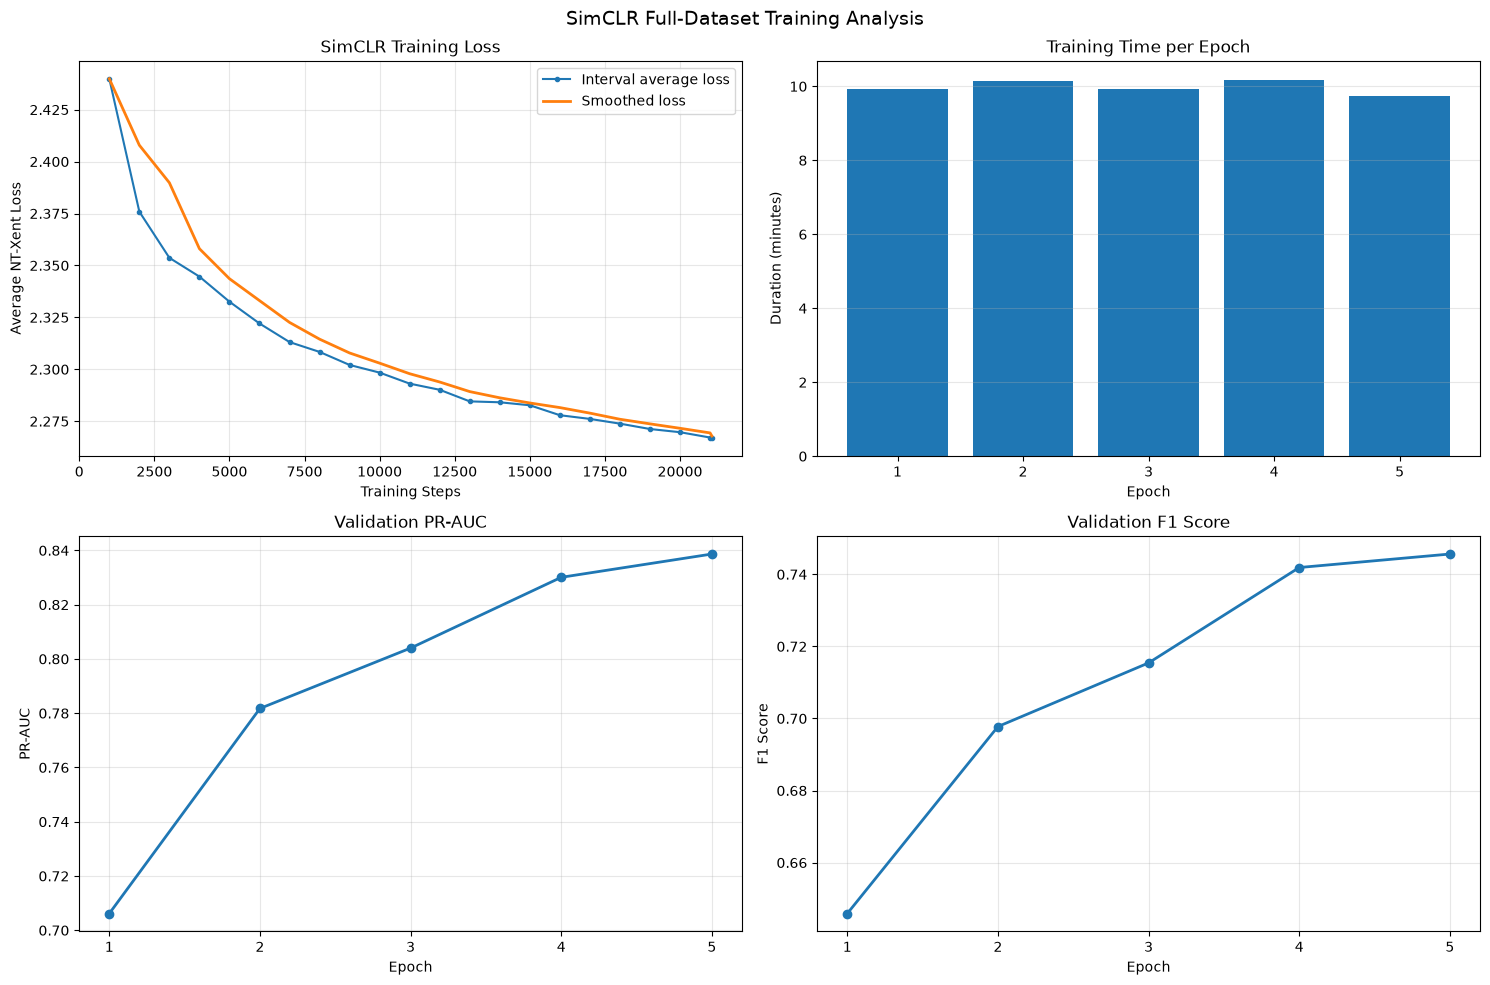

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

history_df = pd.DataFrame(history)
step_df = pd.DataFrame(step_history)

display(history_df)
display(step_df)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Training loss against global steps
axes[0, 0].plot(
    step_df["step"],
    step_df["average_loss"],
    linewidth=1.5,
    marker="o",
    markersize=3,
    label="Interval average loss",
)

if len(step_df) >= 3:
    smoothed_loss = (
        step_df["average_loss"].rolling(window=3, min_periods=1).mean()
    )

    axes[0, 0].plot(
        step_df["step"],
        smoothed_loss,
        linewidth=2,
        label="Smoothed loss",
    )

axes[0, 0].set_title("SimCLR Training Loss")
axes[0, 0].set_xlabel("Training Steps")
axes[0, 0].set_ylabel("Average NT-Xent Loss")
axes[0, 0].grid(alpha=0.3)
axes[0, 0].legend()

# 2. Training duration per epoch
axes[0, 1].bar(
    history_df["epoch"],
    history_df["elapsed_seconds"] / 60,
)

axes[0, 1].set_title("Training Time per Epoch")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Duration (minutes)")
axes[0, 1].set_xticks(history_df["epoch"])
axes[0, 1].grid(axis="y", alpha=0.3)

# 3. Validation PR-AUC
if "val_pr_auc" in history_df.columns:
    axes[1, 0].plot(
        history_df["epoch"],
        history_df["val_pr_auc"],
        marker="o",
        linewidth=2,
    )

    axes[1, 0].set_title("Validation PR-AUC")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("PR-AUC")
    axes[1, 0].set_xticks(history_df["epoch"])
    axes[1, 0].grid(alpha=0.3)

# 4. Validation F1
if "val_f1" in history_df.columns:
    axes[1, 1].plot(
        history_df["epoch"],
        history_df["val_f1"],
        marker="o",
        linewidth=2,
    )

    axes[1, 1].set_title("Validation F1 Score")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("F1 Score")
    axes[1, 1].set_xticks(history_df["epoch"])
    axes[1, 1].grid(alpha=0.3)

plt.suptitle(
    "SimCLR Full-Dataset Training Analysis",
    fontsize=14,
)

plt.tight_layout()
plt.show()

In [29]:
# Load best SimCLR checkpoint
checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best checkpoint")
print("Best checkpoint epoch:", checkpoint["epoch"])
print(
    "Best validation PR-AUC:",
    checkpoint["validation_metrics"]["pr_auc"],
)

Loaded best checkpoint
Best checkpoint epoch: 5
Best validation PR-AUC: 0.8386656227327353


In [30]:
# Reproducible linear-probe initialization
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [31]:
# Evaluate on the held-out test split
print("\nRunning final test evaluation...")

test_metrics = evaluate_linear_probe(
    model=model,
    train_df=train_df,
    val_df=test_df,
    data_dir=DATA_DIR,
)

print("\n" + "=" * 45)
print("FINAL TEST RESULTS")
print("=" * 45)

for metric, value in test_metrics.items():
    print(f"{metric.upper():<15}: {value:.4f}")



Running final test evaluation...

FINAL TEST RESULTS
ACCURACY       : 0.8761
PRECISION      : 0.6831
RECALL         : 0.8197
F1             : 0.7452
PR_AUC         : 0.8363


In [32]:
# Save test results
test_results_df = pd.DataFrame([test_metrics])

test_results_df.to_csv(
    CHECKPOINT_DIR / "simclr_test_results.csv",
    index=False,
)

print("\nTest results saved.")


Test results saved.


Epoch 1/10 | Loss: 0.4253
Epoch 2/10 | Loss: 0.3816
Epoch 3/10 | Loss: 0.3706
Epoch 4/10 | Loss: 0.3638
Epoch 5/10 | Loss: 0.3584
Epoch 6/10 | Loss: 0.3543
Epoch 7/10 | Loss: 0.3512
Epoch 8/10 | Loss: 0.3482
Epoch 9/10 | Loss: 0.3455
Epoch 10/10 | Loss: 0.3442
              precision    recall  f1-score   support

     No Ship       0.94      0.90      0.92     22500
        Ship       0.69      0.80      0.74      6384

    accuracy                           0.88     28884
   macro avg       0.82      0.85      0.83     28884
weighted avg       0.89      0.88      0.88     28884



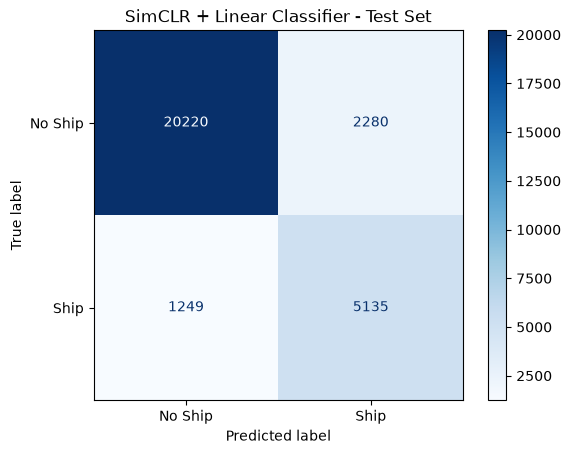

In [33]:
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# 1. Load the best trained SimCLR model
checkpoint = torch.load(
    BEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


# 2. Extract features using the trained encoder
def extract_features(dataframe):
    dataset = AirbusEvaluationDataset(DATA_DIR, dataframe)
    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
    )

    features, labels = [], []

    with torch.inference_mode():
        for images, batch_labels in loader:
            images = images.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP
            ):
                batch_features = model.encoder(images)

            features.append(batch_features.float().cpu())
            labels.append(batch_labels)

    return torch.cat(features), torch.cat(labels)


train_features, train_labels = extract_features(train_df)
test_features, test_labels = extract_features(test_df)

# 3. Create and train the linear classifier
classifier = nn.Linear(train_features.shape[1], 2).to(DEVICE)

class_counts = torch.bincount(train_labels, minlength=2).float()
class_weights = (len(train_labels) / (2 * class_counts)).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(
    classifier.parameters(), lr=1e-3, weight_decay=1e-4
)

train_dataset = TensorDataset(train_features, train_labels)
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True)

classifier.train()

for epoch in range(10):
    total_loss = 0

    for features, labels in train_loader:
        features = features.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = classifier(features)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch + 1}/10 | Loss: {total_loss / len(train_loader):.4f}")

# 4. Predict on the test set
classifier.eval()

with torch.inference_mode():
    test_logits = classifier(test_features.to(DEVICE))
    predictions = test_logits.argmax(dim=1).cpu().numpy()

actual = test_labels.numpy()

# 5. Classification results
print(
    classification_report(
        actual, predictions, target_names=["No Ship", "Ship"]
    )
)

# 6. Confusion matrix
cm = confusion_matrix(actual, predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["No Ship", "Ship"]
).plot(cmap="Blues", values_format="d")

plt.title("SimCLR + Linear Classifier - Test Set")
plt.show()


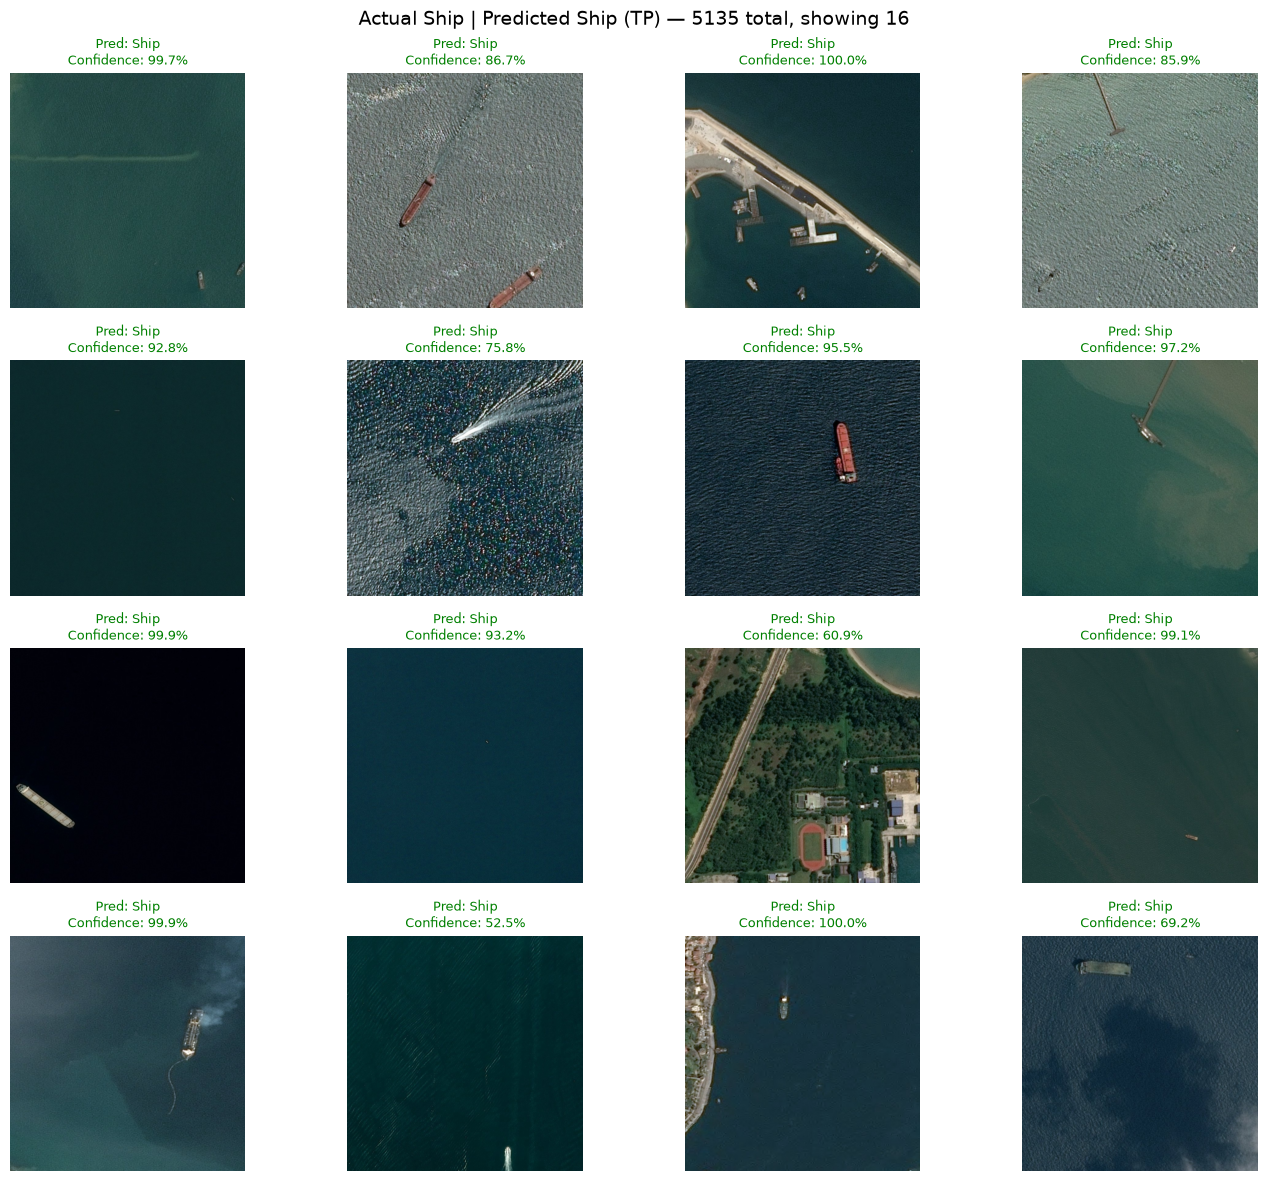

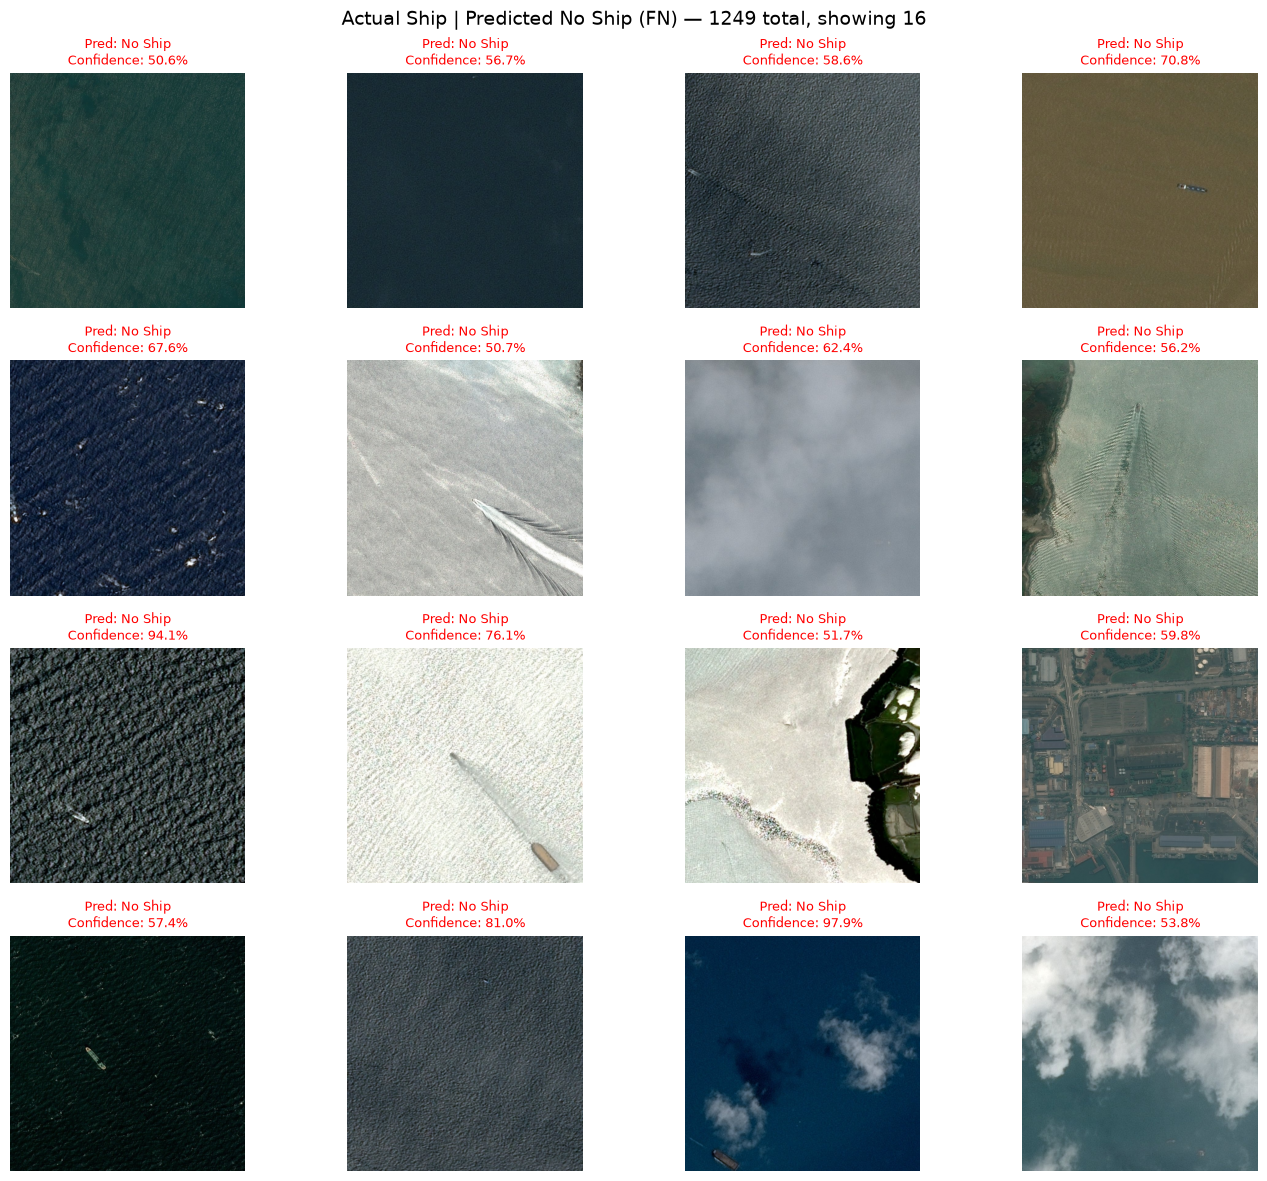

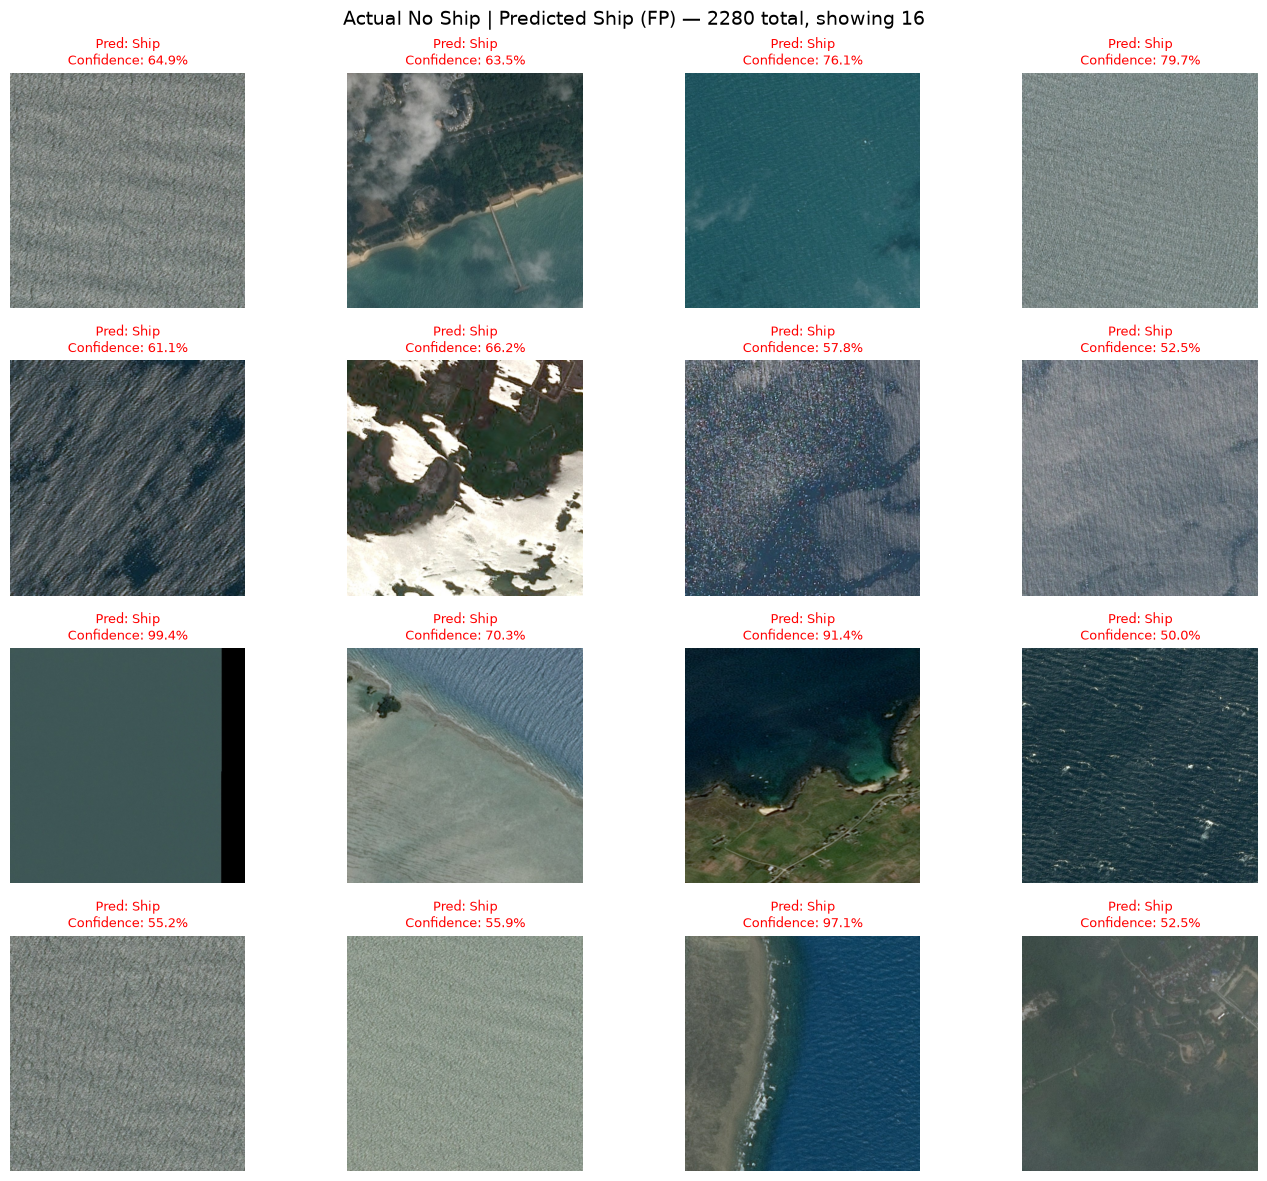

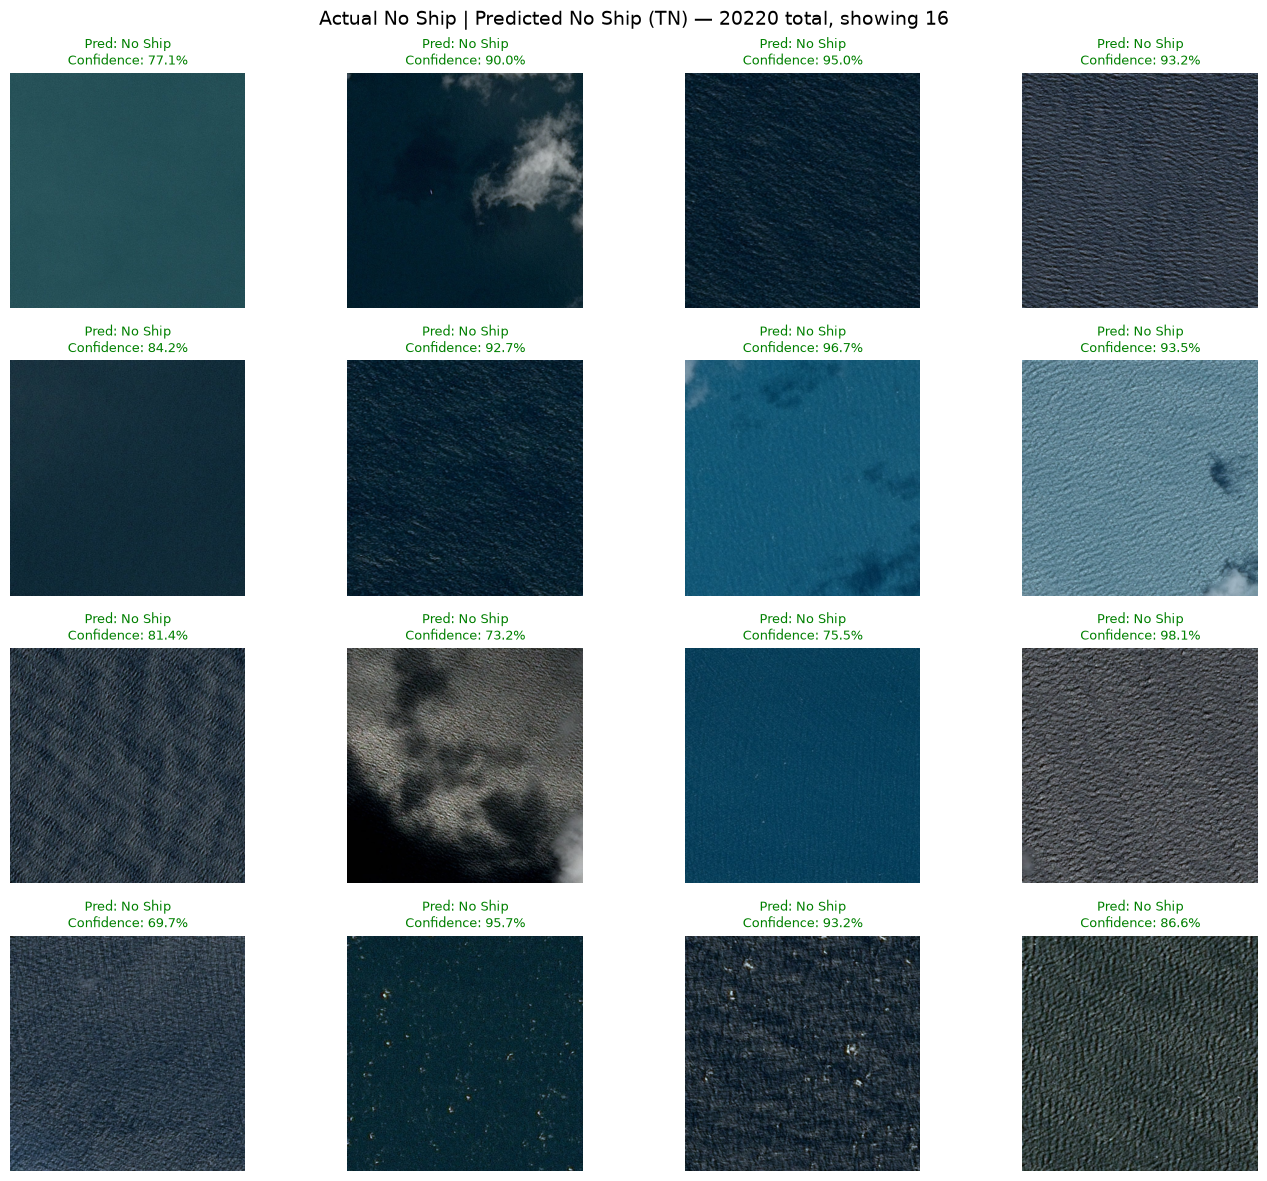

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# Get predictions for the complete test set
classifier.eval()

with torch.inference_mode():
    test_logits = classifier(test_features.to(DEVICE))
    test_predictions = test_logits.argmax(dim=1).cpu().numpy()
    test_probabilities = torch.softmax(test_logits, dim=1).cpu().numpy()

actual_labels = test_labels.numpy()

# Identify the four categories
categories = {
    "Actual Ship | Predicted Ship (TP)": np.where(
        (actual_labels == 1) & (test_predictions == 1)
    )[0],
    "Actual Ship | Predicted No Ship (FN)": np.where(
        (actual_labels == 1) & (test_predictions == 0)
    )[0],
    "Actual No Ship | Predicted Ship (FP)": np.where(
        (actual_labels == 0) & (test_predictions == 1)
    )[0],
    "Actual No Ship | Predicted No Ship (TN)": np.where(
        (actual_labels == 0) & (test_predictions == 0)
    )[0],
}

# Display 16 images from each category
NUM_IMAGES = 16

for category, indices in categories.items():
    selected = np.random.default_rng(42).choice(
        indices, size=min(NUM_IMAGES, len(indices)), replace=False
    )

    fig, axes = plt.subplots(4, 4, figsize=(14, 12))
    axes = axes.flatten()

    for ax, idx in zip(axes, selected):
        image_id = test_df.iloc[idx]["ImageId"]
        image_path = DATA_DIR / image_id

        with Image.open(image_path) as image:
            ax.imshow(image.convert("RGB"))

        predicted = test_predictions[idx]
        confidence = test_probabilities[idx, predicted]

        correct = actual_labels[idx] == test_predictions[idx]

        ax.set_title(
            f"Pred: {'Ship' if predicted else 'No Ship'}\n"
            f"Confidence: {confidence:.1%}",
            fontsize=9,
            color="green" if correct else "red",
        )
        ax.axis("off")

    # Hide unused axes if a category has fewer than 16 images
    for ax in axes[len(selected) :]:
        ax.axis("off")

    fig.suptitle(
        f"{category} — {len(indices)} total, showing {len(selected)}",
        fontsize=14,
    )
    plt.tight_layout()
    plt.show()
